# Titanic survival: from exploration to a measured baseline

**Question:** Can a small, reproducible classifier outperform always predicting the majority class on held-out passengers?

This is a learning exercise on Kaggle's historical [Titanic dataset](https://www.kaggle.com/competitions/titanic/data), not a deployed safety system. The original version explored the full labeled dataset; this revision reserves an 80/20 split before exploration and model selection. That split is untouched by tuning in this workflow, but is not a prospectively collected or previously unseen external dataset.

Run cells in order using the environment in `requirements-dev.txt`. Paths work from the repository root or the `notebook` directory. Re-running writes the documented local result artifacts.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / 'titanic.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'titanic.py').exists():
    raise RuntimeError('Open this notebook from the repository or notebook directory')
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
import titanic

DATA = ROOT / 'data/train.csv'
OUTPUT = ROOT / 'artifacts'
frame = titanic.read_data(DATA)
development, holdout = titanic.split_data(frame)
print(f'{len(frame)} labeled passengers: {len(development)} development, {len(holdout)} holdout')

891 labeled passengers: 712 development, 179 holdout


## 1. Inspect the development data

`PassengerId` identifies rows; it is not a model feature. `Name` contributes a fixed title category. `Ticket` and `Cabin` are omitted from this first model to limit complexity; the latter has extensive missingness. Missing ages, fares and embarkation values will be imputed inside each training fold, not using validation or holdout statistics.

In [2]:
display(development.drop(columns=['Name', 'Ticket', 'Cabin']).describe(include='all'))
display(development.isna().sum().rename('missing').to_frame())

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
count,712.000000,712.000000,712.000000,712,575.000000,712.000000,712.000000,712.000000,710
unique,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,male,NaN,NaN,NaN,NaN,S
freq,NaN,NaN,NaN,459,NaN,NaN,NaN,NaN,516
mean,444.405899,0.383427,2.308989,NaN,29.807687,0.492978,0.390449,31.819826,NaN
std,257.465527,0.486563,0.833563,NaN,14.485211,1.060720,0.838134,48.059104,NaN
min,1.000000,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN
25%,222.750000,0.000000,2.000000,NaN,21.000000,0.000000,0.000000,7.895800,NaN
50%,439.500000,0.000000,3.000000,NaN,28.500000,0.000000,0.000000,14.454200,NaN
75%,667.250000,1.000000,3.000000,NaN,39.000000,1.000000,0.000000,31.000000,NaN


,missing
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,137
SibSp,0
Parch,0
Ticket,0
Fare,0


## 2. Explore patterns, without treating them as causes

Compare survival proportions and group sizes. Sex and ticket class show association with the outcome in this historical sample. These comparisons do not establish why any individual survived, and they are not model accuracy. Small family groups need particular caution because their proportions can change with only a few passengers.

Development rows: 712; survival rate: 38.3%
Missing values:
 Age         137
Embarked      2


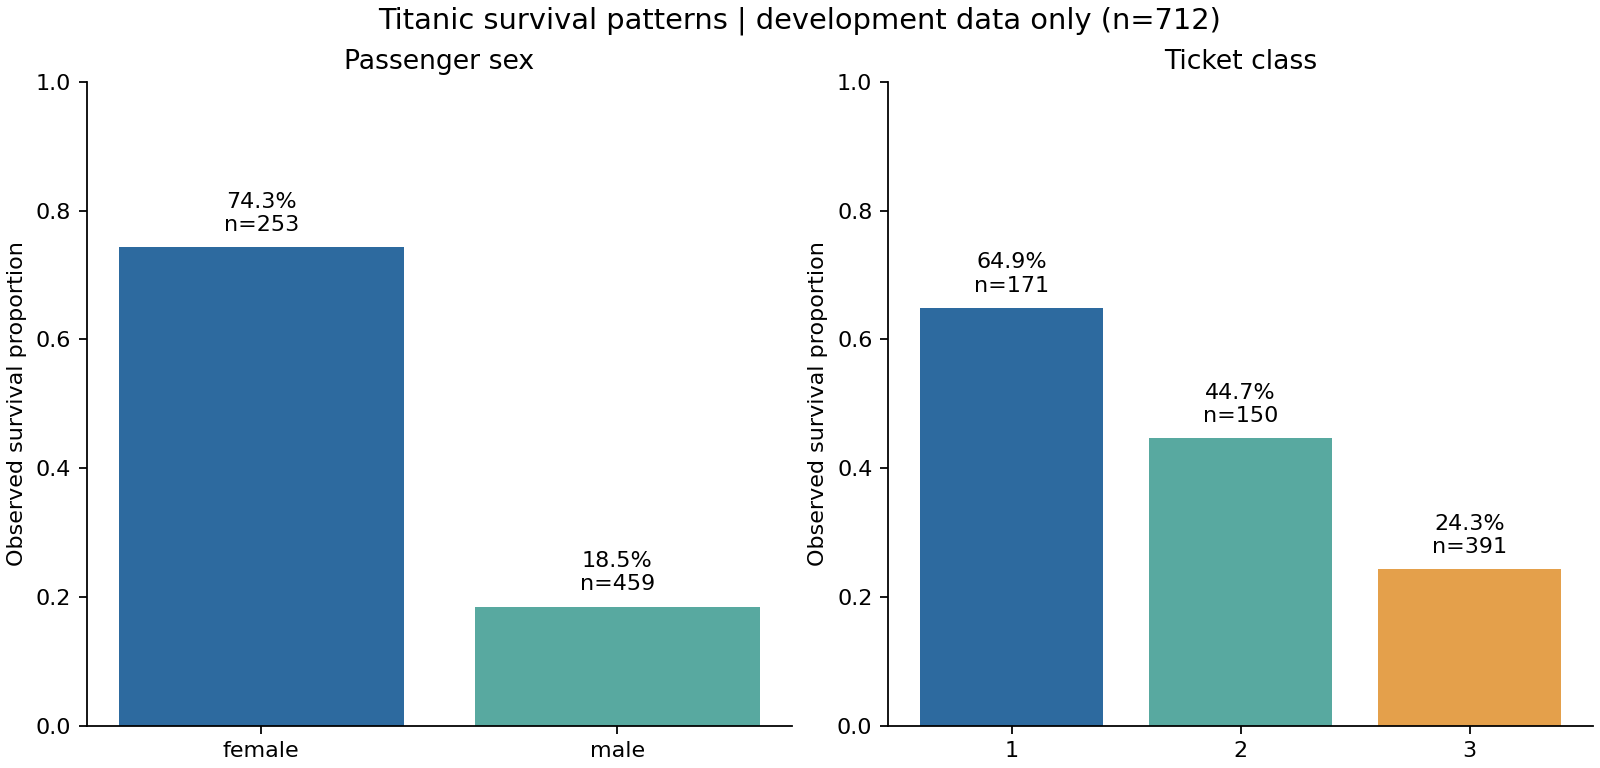

,survival_rate,passengers
FamilySize,,
1,0.299539,434
2,0.550388,129
3,0.623377,77
4,0.727273,22
5,0.214286,14
6,0.062500,16
7,0.363636,11
8,0.000000,4
11,0.000000,5


In [3]:
titanic.eda(DATA, ROOT / 'images')
display(Image(filename=str(ROOT / 'images/survival_patterns.png')))
family = development.assign(FamilySize=development.SibSp + development.Parch + 1)
display(family.groupby('FamilySize').Survived.agg(survival_rate='mean', passengers='size'))

## 3. Define features before fitting

`FamilySize = SibSp + Parch + 1`; `IsAlone` marks family size one. Title parsing uses a fixed rule (Mr/Mrs/Miss/Master, with other titles grouped as Rare). These operations read only the current passenger and cannot learn from outcome labels. Numeric imputation, scaling, category imputation and one-hot encoding are fitted by a scikit-learn `Pipeline` inside each fold. Unknown categories are tolerated at prediction time.

In [4]:
display(titanic.add_features(development).head())

,Age,Fare,SibSp,Parch,FamilySize,IsAlone,Pclass,Sex,Embarked,Title
692,NaN,56.4958,0,0,1,1,3,male,S,Mr
481,NaN,0.0000,0,0,1,1,2,male,S,Mr
527,NaN,221.7792,0,0,1,1,1,male,S,Mr
855,18.0,9.3500,0,1,2,0,3,female,S,Mrs
801,31.0,26.2500,1,1,3,0,2,female,S,Mrs


## 4. Choose a model using development-only cross-validation

Compare a majority-class dummy, logistic regression, and a modest random forest. All candidates and hyperparameters are fixed in `titanic.py`; no broad hyperparameter search is performed. Five stratified folds use seed 42. Select mean **balanced accuracy**, the average recall of the two classes, so majority-class performance alone cannot win by ignoring survivors. Fold standard deviations describe fold variation, not confidence intervals.

The holdout is not used to choose the model or tune a threshold. Preprocessing is refitted separately inside every CV fold.

In [5]:
selection = titanic.train(DATA, OUTPUT)
cv = pd.read_csv(OUTPUT / 'cv_results.csv')
display(cv.groupby('model')[['accuracy', 'balanced_accuracy', 'roc_auc']].agg(['mean', 'std']))

                    accuracy         balanced_accuracy         roc_auc        
                        mean     std              mean     std    mean     std
model                                                                         
dummy_majority        0.6166  0.0031            0.5000  0.0000  0.5000  0.0000
logistic_regression   0.8217  0.0228            0.8063  0.0214  0.8664  0.0220
random_forest         0.8230  0.0278            0.8017  0.0289  0.8711  0.0291
Selected logistic_regression; the 179 holdout labels were not used in model selection.


accuracy           balanced_accuracy             roc_auc  \
                         mean       std              mean       std      mean   
model                                                                           
dummy_majority       0.616576  0.003074          0.500000  0.000000  0.500000   
logistic_regression  0.821659  0.022821          0.806280  0.021375  0.866412   
random_forest        0.823047  0.027758          0.801744  0.028910  0.871061   

                               
                          std  
model                          
dummy_majority       0.000000  
logistic_regression  0.022029  
random_forest        0.029072

## 5. Evaluate the selected model once and inspect its errors

Use the frozen development model on 179 holdout passengers. The classification threshold is the estimator default (0.5); do not alter it after inspecting these results. Inspect false positives and false negatives and subgroup counts to understand failures. Group differences on this small test split are exploratory, not a fairness certification. Related passengers can cross a random split; a family-grouped or external evaluation is a future robustness check.

{
  "selected_model": "logistic_regression",
  "holdout_rows": 179,
  "threshold": 0.5,
  "positive_class": "Survived=1",
  "model": {
    "accuracy": 0.8379888268156425,
    "balanced_accuracy": 0.822266139657444,
    "precision": 0.8125,
    "recall": 0.7536231884057971,
    "f1": 0.7819548872180451,
    "roc_auc": 0.8799736495388669,
    "confusion_matrix": [
      [
        98,
        12
      ],
      [
        17,
        52
      ]
    ]
  },
  "dummy_majority": {
    "accuracy": 0.6145251396648045,
    "balanced_accuracy": 0.5,
    "precision": 0.0,
    "recall": 0.0,
    "f1": 0.0,
    "roc_auc": 0.5,
    "confusion_matrix": [
      [
        110,
        0
      ],
      [
        69,
        0
      ]
    ]
  },
  "note": "One fixed holdout. No threshold tuning on holdout; no Kaggle test labels are available."
}


,model,dummy_majority
accuracy,0.8380,0.6145
balanced_accuracy,0.8223,0.5000
precision,0.8125,0.0000
recall,0.7536,0.0000
f1,0.7820,0.0000
roc_auc,0.8800,0.5000


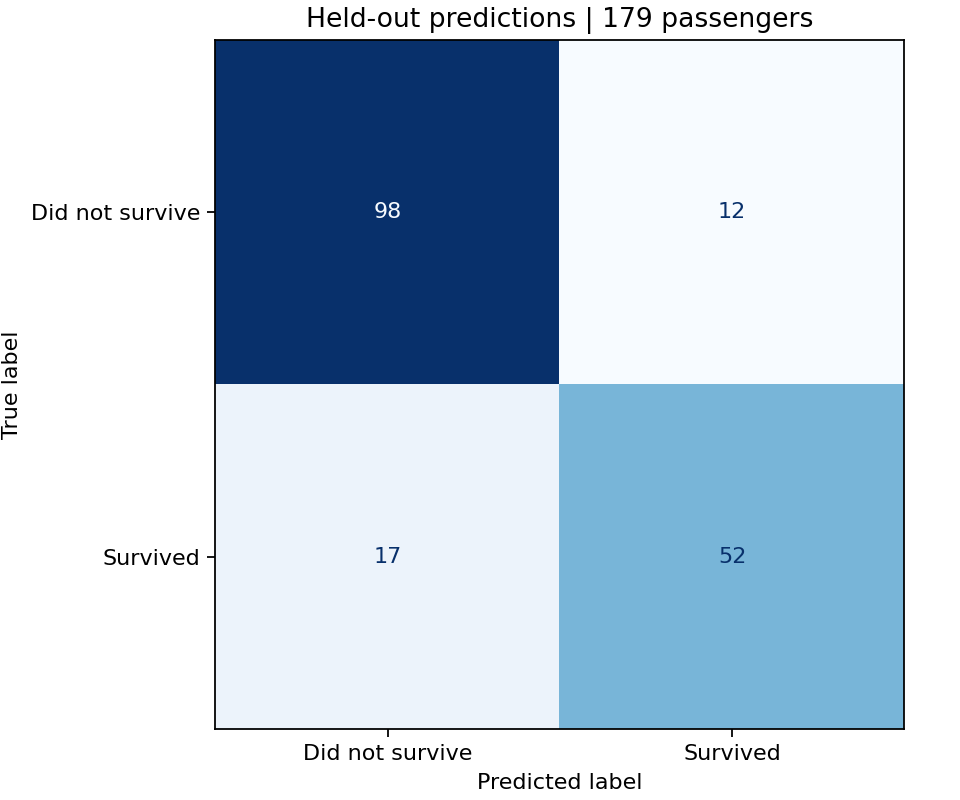

,feature,group,n,errors,accuracy
0,Sex,female,61,11,0.819672
1,Sex,male,118,18,0.847458
2,Pclass,1,45,10,0.777778
3,Pclass,2,34,3,0.911765
4,Pclass,3,100,16,0.840000


,PassengerId,Pclass,Sex,Age,Survived,Predicted,SurvivalProbability,Correct,ErrorType
4,18,2,male,NaN,1,0,0.146837,False,false_negative
5,24,1,male,28.0,1,0,0.416733,False,false_negative
8,39,3,female,18.0,0,1,0.502552,False,false_positive
10,41,3,female,40.0,0,1,0.618624,False,false_positive
11,56,1,male,NaN,1,0,0.347032,False,false_negative
13,66,3,male,NaN,1,0,0.445680,False,false_negative
31,147,3,male,27.0,1,0,0.086543,False,false_negative
41,200,2,female,24.0,0,1,0.798959,False,false_positive
47,246,1,male,44.0,0,1,0.521296,False,false_positive
49,272,3,male,25.0,1,0,0.089213,False,false_negative


In [6]:
report = titanic.evaluate(DATA, OUTPUT)
display(pd.DataFrame({key: {m: v for m, v in report[key].items() if m != 'confusion_matrix'} for key in ['model', 'dummy_majority']}).round(4))
display(Image(filename=str(OUTPUT / 'holdout_confusion_matrix.png')))
display(pd.read_csv(OUTPUT / 'subgroup_errors.csv'))
errors = pd.read_csv(OUTPUT / 'holdout_predictions.csv')
display(errors.loc[errors.ErrorType != 'correct'].head(10))

## 6. Predict the unlabeled Kaggle rows

After measuring the fixed model, refit the selected specification on all 891 labeled passengers to create a submission for the 418 unlabeled rows. This does not replace the development model or change its recorded holdout result. There are no test labels in `test.csv`; the sample `gender_submission.csv` is not ground truth. No Kaggle leaderboard score is claimed.

In [7]:
submission = titanic.predict(DATA, ROOT / 'data/test.csv', OUTPUT)
display(submission.head())
print(submission.shape)

Wrote 418 predictions; refit on 891 labeled passengers. No test accuracy is available.

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


(418, 2)


## Conclusions and limits

Read the actual comparison above and `artifacts/metrics.json`; the outcome is measured rather than assumed. One fixed split cannot establish stable performance. This dataset is small, famous and historically biased, so it demonstrates a workflow more than a novel scientific result. A later version should define a family-aware split in advance, evaluate additional seeds without tuning to this holdout, and compare feature ablations before claiming an improvement. A deployed demo and CI result from GitHub are not claimed here.